# Proyecto Final (Hito 4) — Minería de Datos (Data Hunters)
## Segmentación y Detección Georreferenciada de Descalce en Obras Públicas del Sistema Invierte.pe

**Integrantes:**
- Fernando Torres Valdivia
- Romy Tipacti Carrasco
- Arturo Álvarez de la Torre

**Docente:** Soledad Espezúa Llerena  
**Curso:** Data Mining — Universidad del Pacífico  
**Repositorio GitHub:** `https://github.com/RomyUP1411/data-mining-project`

---

# <font color=blue>I. Introducción</font>

- **Contexto y problema:** El Sistema Nacional de Programación Multianual y Gestión de Inversiones (**Invierte.pe**) conduce la asignación de recursos públicos para infraestructura en el Perú. Pese a la magnitud del presupuesto anual, la supervisión operativa enfrenta una desconexión crítica: el módulo presupuestal (`Seguimiento_PI` del MEF) registra los desembolsos financieros devengados, mientras que el sistema de contrataciones (`Proceso_Seleccion` del SEACE e Infobras) registra por separado los contratos y el porcentaje de avance físico en campo. Esta falta de conciliación periódica origina el problema del **descalce financiero-físico**: obras que devengan gran parte de su presupuesto sin registrar un avance físico equivalente, o que acumulan cientos de contratos y adendas durante más de una década, desembocando en sobrecostos y obras paralizadas.
- **Usuario y beneficiarios del proyecto:** Los resultados de este trabajo benefician directamente a tres usuarios:
  1. **Contraloría General de la República (CGR) y Órganos de Control Institucional (OCI):** pasan de revisar manualmente miles de expedientes a contar con un filtro objetivo de triaje sobre las obras atípicas de mayor riesgo.
  2. **Dirección General de Programación Multianual de Inversiones (DGPMI - MEF):** obtiene tipologías empíricas para diferenciar el seguimiento presupuestal entre ministerios, gobiernos regionales y municipalidades.
  3. **Unidades Ejecutoras subnacionales y ciudadanía:** permite detectar cuellos de botella contractuales en obras de salud, saneamiento, educación y transporte antes de que queden paralizadas.
- **Objetivo del proyecto:** Segmentar de manera no supervisada la cartera activa de proyectos de inversión pública ($N = 2,066$ CUI, tras excluir el outlier extremo de la Línea 2 del Metro de Lima) para caracterizar tipologías operativas de ejecución, aislar proyectos atípicos (*outliers*) con DBSCAN, interpretar la estructura interna de dicho ruido mediante **PCA y NMF**, y georreferenciar los proyectos atípicos en GeoPandas y **Folium (`mapa_clusters.html`)** para orientar la priorización del control gubernamental.
- **Pregunta de análisis:** *¿Es posible identificar tipologías estructurales de proyectos de inversión pública y caracterizar territorialmente los perfiles atípicos de descalce financiero-físico mediante técnicas de clustering no supervisado y reducción dimensional sobre el ruido aplicadas a datos transaccionales del MEF?*
- **Aporte del trabajo:** Frente a la supervisión tradicional basada únicamente en el monto de la obra, este trabajo aporta: (i) una matriz analítica depurada a nivel de proyecto CUI ($N = 2,066$) que evita la distorsión de escala del megaproyecto Línea 2 del Metro; (ii) la triangulación de **K-Means ($K=3$)**, **Jerárquico Ward ($K=3$)** y **DBSCAN ($arepsilon=1.8$)**, logrando capturar en el $10.41\%$ de ruido de DBSCAN ($215$ obras) una tasa de alerta crítica ($33.02\%$) que casi triplica a los clusters densos ($11.40\%$); (iii) la aplicación focalizada de **PCA y NMF sobre los 215 proyectos marcados como ruido** para descomponer los factores latentes que explican su anomalía; (iv) mapas estáticos y un mapa interactivo multicapa en **Folium (`mapa_clusters.html`)** centrados en los proyectos en ruido por región; y (v) una regla operativa (`scaler.transform`, percentil 95 de distancia al centroide y vecindad a puntos núcleo) para evaluar nuevos proyectos sin reentrenar los modelos.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8.5, 4.5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# <font color=blue>II. Datos, Tratamiento de Outlier Extremo y Representación Final</font>

## <font color=green>1. Fuentes, exclusión de la Línea 2 del Metro de Lima y atributos seleccionados</font>

La matriz analítica (`matriz_analitica_final.csv`) integra los registros de **`Seguimiento_PI`** (ejecución presupuestal del MEF) y **`Proceso_Seleccion`** (contratos y avance físico reportado), junto con los shapefiles oficiales del **Instituto Geográfico Nacional (IGN)** (`peru_shapes`).

- **Tratamiento previo de outlier extremo:** Al revisar los montos de inversión antes de escalar, la *Construcción de la Línea 2 y Ramal Av. Faucett-Gambetta del Metro de Lima y Callao* (`codigo_proyecto = 2233850`, S/ $12,075.45$ millones) supera en más de **5 veces** al segundo proyecto más grande de todo el Perú (Majes Siguas II, S/ $2,330.94$ millones). Dado que `StandardScaler` cambia la escala pero no corrige outliers extremos, mantener ese registro comprime la varianza de las demás obras y fuerza la aparición de un cluster unitario artificial ($n = 1$). Por ello, lo retiramos antes del escalamiento, trabajando con **$N = 2,066$ proyectos activos**.
- **Atributos que entran al cálculo de distancias (12 variables):**
  1. **Descalce y ejecución:** `pct_ejecucion_financiera`, `avance_fisico_pct`, `brecha_gasto_avance` ($	ext{\% gasto} - 	ext{\% avance físico}$).
  2. **Magnitud presupuestal:** `costo_inversion`, `gasto_total`, `gasto_anual_promedio`.
  3. **Maduración y contratación:** `tiempo_maduracion_anios`, `n_registros_presupuesto`, `n_contratos`, `tamano_inversion_ord`.
  4. **Nivel de gobierno (One-Hot):** `gob_GOBIERNOS LOCALES`, `gob_GOBIERNOS REGIONALES` (Gobierno Nacional como categoría base).
- **Exclusiones y escalamiento:** Excluimos identificadores (`codigo_proyecto`, `nombre_proyecto`), región (`departamento`, reservada para la georreferenciación) y la variable de alerta **`flag_gasto_adelantado`** (1 si `brecha_gasto_avance > 15%`, 0 si no), la cual **no participa** en las distancias y se usa al final para evaluar el riesgo de cada grupo. Estandarizamos los 12 atributos con **`StandardScaler`** (`X_std`).

In [2]:
if os.path.exists("matriz_analitica_final.csv"):
    ruta_datos = "matriz_analitica_final.csv"
else:
    ruta_datos = "Entrega_4/matriz_analitica_final.csv"

df_raw = pd.read_csv(ruta_datos)

print("Top 5 proyectos por costo de inversión en la base original:")
display(df_raw.nlargest(5, "costo_inversion")[["codigo_proyecto", "nombre_proyecto", "departamento", "costo_inversion", "gasto_total", "n_contratos"]])

# Descartamos la Línea 2 del Metro de Lima (CUI 2233850) antes de estandarizar
df = df_raw[df_raw["codigo_proyecto"] != 2233850].reset_index(drop=True)
print(f"Proyectos originales: {len(df_raw)} -> Proyectos tras excluir Línea 2 del Metro: {len(df)}")

features = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos",
    "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES",
    "gob_GOBIERNOS REGIONALES"
]

X = df[features].copy()

# Estandarizamos las 12 variables sobre la base depurada (N = 2,066)
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

df_resultados = df.copy()

print("Dimensiones de X_std:", X_std.shape)
display(df[["codigo_proyecto", "nombre_proyecto", "nivel_gobierno", "departamento", "costo_inversion", "avance_fisico_pct", "brecha_gasto_avance", "n_contratos"]].head(3))

Top 5 proyectos por costo de inversión en la base original:


,codigo_proyecto,nombre_proyecto,departamento,costo_inversion,gasto_total,n_contratos
680,2233850,CONSTRUCCION DE LA LINEA 2 Y RAMAL AV. FAUCETT...,LIMA,12075451952.74,1837811051.69,72.00
83,2088142,MAJES SIGUAS - II ETAPA,AREQUIPA,2330935518.48,195999483.00,398.00
60,2077997,PROYECTO CHAVIMOCHIC TERCERA ETAPA,LA LIBERTAD,1484690667.94,339263715.01,64.00
455,2190272,MEJORAMIENTO Y AMPLIACION DEL SERVICIO AEROPOR...,LIMA,1471628346.05,458650575.64,124.00
813,2250145,INSTALACION DE BANDA ANCHA PARA LA CONECTIVIDA...,LIMA,1012131644.41,185043138.00,101.00


Proyectos originales: 2067 -> Proyectos tras excluir Línea 2 del Metro: 2066
Dimensiones de X_std: (2066, 12)


,codigo_proyecto,nombre_proyecto,nivel_gobierno,departamento,costo_inversion,avance_fisico_pct,brecha_gasto_avance,n_contratos
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,GOBIERNO NACIONAL,LIMA,263517133.53,100.00,-29.71,63.00
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,GOBIERNO NACIONAL,LIMA,269114681.55,100.00,-35.35,27.00
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,GOBIERNOS REGIONALES,ANCASH,189747493.86,100.00,-63.39,38.00


# <font color=blue>III. Metodología y Diseño Experimental</font>

## <font color=green>2. Evaluación de K-Means: Codo de Inercia, Silhouette y Davies-Bouldin ($K = 2, \dots, 8$)</font>

Nuestro flujo evalúa primero los tres algoritmos de clustering sobre la matriz estandarizada `X_std` (**K-Means**, **Jerárquico de Ward** y **DBSCAN**). Una vez identificados los **proyectos atípicos marcados como ruido por DBSCAN (`cluster_dbscan = -1`)**, aplicamos **PCA y NMF sobre dicho subconjunto de ruido** para interpretar qué dimensiones explican sus anomalías y los representamos espacialmente con **GeoPandas y Folium (`mapa_clusters.html`)**.

Para seleccionar $K$ en **K-Means**, comparamos $K \in [2, 8]$ (`k-means++`, `n_init=10`, `random_state=42`) con tres métricas internas y dos criterios prácticos:
- **Inercia:** baja al crecer $K$; buscamos el **codo** donde la reducción porcentual se desacelera.
- **Silhouette:** entre $-1$ y $1$; **más alto es mejor**.
- **Davies-Bouldin:** $\ge 0$; **más bajo es mejor**.
- **`segmento_mas_pequeno` y `dif_alerta`:** tamaño del grupo más pequeño y diferencia de tasas de alerta entre segmentos.

Evaluación de K-Means para K = 2, ..., 8 (Inercia en K=1: 24792.00):


,K,inercia,reduccion_inercia_%,silhouette,davies_bouldin,segmento_mas_pequeno,dif_alerta
0,2,20229.36,18.40,0.28,1.75,633,0.02
1,3,16992.16,16.00,0.22,1.48,55,0.06
2,4,15352.37,9.65,0.21,1.61,25,0.11
3,5,13867.51,9.67,0.21,1.49,18,0.88
4,6,12512.83,9.77,0.22,1.35,18,0.96
5,7,11493.22,8.15,0.22,1.31,18,0.98
6,8,10528.11,8.40,0.23,1.26,16,0.98


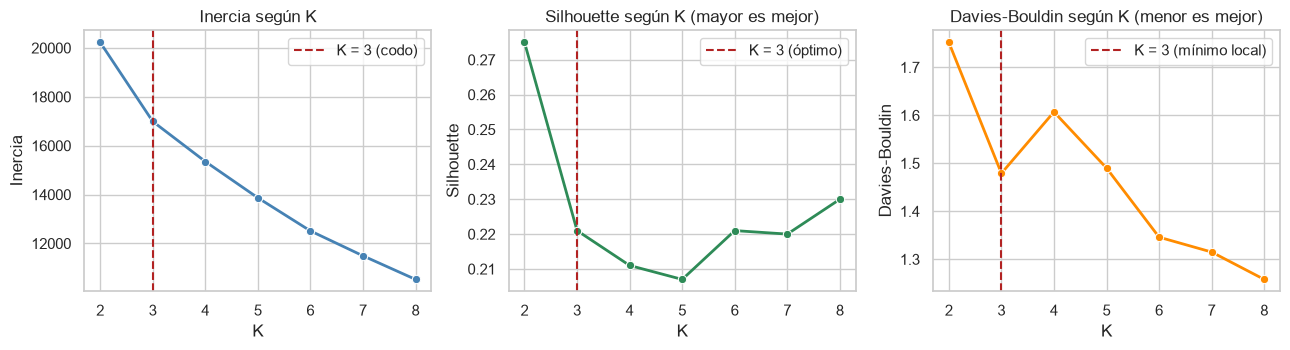

In [3]:
inercia_k1 = KMeans(n_clusters=1, init="k-means++", n_init=10, random_state=42).fit(X_std).inertia_

resultados_kmeans = []
inercia_prev = inercia_k1

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    labels = modelo.fit_predict(X_std)

    alerta = df_resultados.groupby(labels)["flag_gasto_adelantado"].mean()
    tamanos = pd.Series(labels).value_counts()
    reduccion = inercia_prev - modelo.inertia_
    reduccion_pct = (reduccion / inercia_prev) * 100
    inercia_prev = modelo.inertia_

    resultados_kmeans.append({
        "K": k,
        "inercia": round(modelo.inertia_, 2),
        "reduccion_inercia_%": round(reduccion_pct, 2),
        "silhouette": round(silhouette_score(X_std, labels), 3),
        "davies_bouldin": round(davies_bouldin_score(X_std, labels), 3),
        "segmento_mas_pequeno": int(tamanos.min()),
        "dif_alerta": round(alerta.max() - alerta.min(), 3)
    })

metricas_kmeans = pd.DataFrame(resultados_kmeans)
print("Evaluación de K-Means para K = 2, ..., 8 (Inercia en K=1: {:.2f}):".format(inercia_k1))
display(metricas_kmeans)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

sns.lineplot(data=metricas_kmeans, x="K", y="inercia", marker="o", color="steelblue", linewidth=2, ax=axes[0])
axes[0].axvline(3, color="firebrick", linestyle="--", label="K = 3 (codo)")
axes[0].set(title="Inercia según K", xlabel="K", ylabel="Inercia")
axes[0].legend()

sns.lineplot(data=metricas_kmeans, x="K", y="silhouette", marker="o", color="seagreen", linewidth=2, ax=axes[1])
axes[1].axvline(3, color="firebrick", linestyle="--", label="K = 3 (óptimo)")
axes[1].set(title="Silhouette según K (mayor es mejor)", xlabel="K", ylabel="Silhouette")
axes[1].legend()

sns.lineplot(data=metricas_kmeans, x="K", y="davies_bouldin", marker="o", color="darkorange", linewidth=2, ax=axes[2])
axes[2].axvline(3, color="firebrick", linestyle="--", label="K = 3 (mínimo local)")
axes[2].set(title="Davies-Bouldin según K (menor es mejor)", xlabel="K", ylabel="Davies-Bouldin")
axes[2].legend()

plt.tight_layout()
plt.show()

## <font color=green>3. Calibración de DBSCAN (`k-distancias`) y comparación de enlaces en Clustering Jerárquico ($K = 3$)</font>

- **En K-Means:** seleccionamos **`K_ELEGIDO = 3`**. En $K=2$ solo se separa el nivel municipal del resto (`dif_alerta = 0.024`). En **$K=3$** se produce el codo de inercia (`-16.00%`), el **Silhouette alcanza su pico de `0.221`** (superando a $K=4$ con `0.211` y $K=5$ con `0.207`) y el **Davies-Bouldin baja a un mínimo local de `1.479`** (frente al deterioro en $K=4$ donde sube a `1.607`), manteniendo grupos de tamaño representativo (`min = 55`).
- **En DBSCAN:** con `min_samples = 24` ($2 \times 12$ variables), ordenamos la distancia al vecino 24 e identificamos el codo en **`eps = 1.8`**, donde se estabilizan **3 clusters densos (`1,851` obras)** y se aísla un **`10.41%` de ruido (`215` proyectos atípicos)**.
- **En Jerárquico:** comparamos `single`, `complete`, `average` y `ward` en $K = 3$, verificando que `ward` genera 3 grupos equilibrados (`1,078 / 960 / 28`) sin sufrir encadenamiento.

Sensibilidad de DBSCAN según eps (min_samples = 24):


,eps,n_clusters,n_ruido,ruido_%
0,1.20,3,688,33.30
1,1.50,3,344,16.65
2,1.80,3,215,10.41
3,2.00,3,175,8.47
4,2.20,2,145,7.02
5,2.50,1,113,5.47


Comparación de criterios de enlace jerárquico para K = 3:


,linkage,n_clusters,segmento_mas_pequeno,segmento_mas_grande,silhouette
0,single,3,1,2062,0.79
1,complete,3,9,2041,0.64
2,average,3,3,2054,0.78
3,ward,3,28,1078,0.19


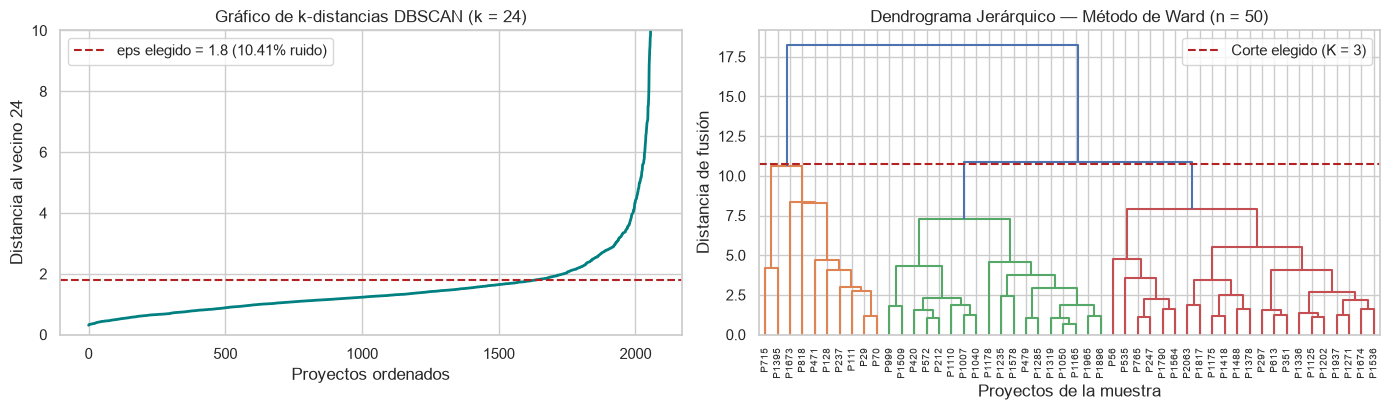

In [4]:
min_samples = 24
vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_std)
distancias, _ = vecinos.kneighbors(X_std)
k_dist = np.sort(distancias[:, min_samples - 1])

comparacion_eps = []
for eps in [1.2, 1.5, 1.8, 2.0, 2.2, 2.5]:
    labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_std)
    etiquetas = set(labels_db)
    n_clusters = len(etiquetas) - (1 if -1 in etiquetas else 0)
    n_ruido = int(np.sum(labels_db == -1))
    comparacion_eps.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "n_ruido": n_ruido,
        "ruido_%": round((n_ruido / len(X_std)) * 100, 2)
    })

print("Sensibilidad de DBSCAN según eps (min_samples = 24):")
display(pd.DataFrame(comparacion_eps))

# Comparación de enlaces jerárquicos para K = 3
resumen_linkage = []
for metodo in ["single", "complete", "average", "ward"]:
    labels_h = AgglomerativeClustering(n_clusters=3, linkage=metodo).fit_predict(X_std)
    conteos = pd.Series(labels_h).value_counts()
    resumen_linkage.append({
        "linkage": metodo,
        "n_clusters": len(conteos),
        "segmento_mas_pequeno": int(conteos.min()),
        "segmento_mas_grande": int(conteos.max()),
        "silhouette": round(silhouette_score(X_std, labels_h), 3)
    })

print("Comparación de criterios de enlace jerárquico para K = 3:")
display(pd.DataFrame(resumen_linkage))

np.random.seed(42)
indices_muestra = np.random.choice(len(df), size=50, replace=False)
Z_ward_muestra = linkage(X_std[indices_muestra], method="ward")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

ax1.plot(k_dist, color="teal", linewidth=2)
ax1.axhline(y=1.8, color="firebrick", linestyle="--", label="eps elegido = 1.8 (10.41% ruido)")
ax1.set_ylim(0, 10)
ax1.set(title=f"Gráfico de k-distancias DBSCAN (k = {min_samples})", xlabel="Proyectos ordenados", ylabel=f"Distancia al vecino {min_samples}")
ax1.legend()

plt.sca(ax2)
dendrogram(Z_ward_muestra, labels=[f"P{i}" for i in indices_muestra], leaf_rotation=90, leaf_font_size=7, color_threshold=10.75)
ax2.axhline(y=10.75, color="firebrick", linestyle="--", label="Corte elegido (K = 3)")
ax2.set(title="Dendrograma Jerárquico — Método de Ward (n = 50)", xlabel="Proyectos de la muestra", ylabel="Distancia de fusión")
ax2.legend()

plt.tight_layout()
plt.show()

# <font color=blue>IV. Resultados de la Segmentación y Detección de Ruido</font>

## <font color=green>4. Configuración final de K-Means ($K = 3$), Silhouette por proyecto y perfil de segmentos</font>

Ajustamos K-Means con `K_ELEGIDO = 3` sobre los 2,066 proyectos, revisamos la distribución de $s(i)$ por proyecto (`silhouette_samples`) y calculamos el perfil promedio en unidades originales junto con el mapa de calor en valores Z.

Resumen de Silhouette por segmento en K-Means (K = 3):


,n,silueta_media,n_negativos
cluster_kmeans,,,
0,55,0.15,16
1,1001,0.33,0
2,1010,0.12,190


Perfil promedio por segmento en unidades originales (K = 3):


,n,porcentaje_%,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tasa_alerta_%
cluster_kmeans,,,,,,,,,,,,
0,55,2.66,41.37,67.90,-26.54,525961133.98,184300044.61,14.53,12940887.21,24.87,184.60,18.18
1,1001,48.45,62.63,79.24,-16.61,5225210.63,2462061.22,9.24,274521.60,9.92,123.28,15.08
2,1010,48.89,44.62,73.49,-28.87,38020307.15,12089135.26,12.38,1012947.91,17.14,211.22,11.98


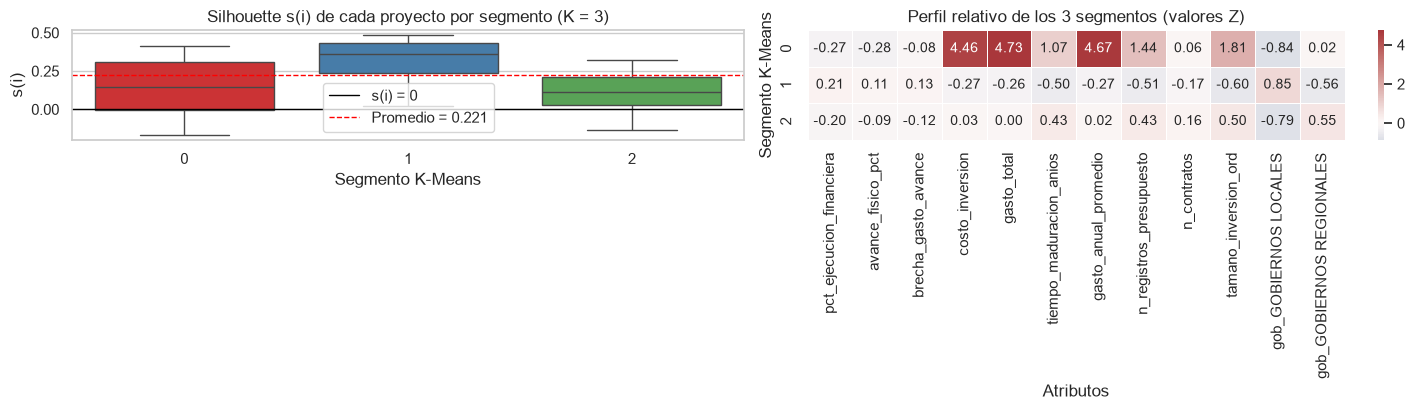

In [5]:
K_ELEGIDO = 3
kmeans_final = KMeans(n_clusters=K_ELEGIDO, init="k-means++", n_init=10, random_state=42)
df_resultados["cluster_kmeans"] = kmeans_final.fit_predict(X_std)
df_resultados["silhouette_km"] = silhouette_samples(X_std, df_resultados["cluster_kmeans"])

promedio_sil = df_resultados["silhouette_km"].mean()
resumen_sil_seg = (
    df_resultados.groupby("cluster_kmeans")["silhouette_km"]
    .agg(n="count", silueta_media="mean", n_negativos=lambda s: (s < 0).sum())
    .round(3)
)
print("Resumen de Silhouette por segmento en K-Means (K = 3):")
display(resumen_sil_seg)

atributos_perfil = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos"
]

conteo_km = df_resultados["cluster_kmeans"].value_counts().sort_index()
porcentaje_km = (df_resultados["cluster_kmeans"].value_counts(normalize=True).sort_index() * 100).round(2)
promedios_km = df_resultados.groupby("cluster_kmeans")[atributos_perfil].mean().round(2)
alerta_km = (df_resultados.groupby("cluster_kmeans")["flag_gasto_adelantado"].mean() * 100).round(2)

perfil_km = promedios_km.copy()
perfil_km["n"] = conteo_km
perfil_km["porcentaje_%"] = porcentaje_km
perfil_km["tasa_alerta_%"] = alerta_km
columnas_orden = ["n", "porcentaje_%"] + atributos_perfil + ["tasa_alerta_%"]
perfil_km = perfil_km[columnas_orden]

print("Perfil promedio por segmento en unidades originales (K = 3):")
display(perfil_km)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))

sns.boxplot(data=df_resultados, x="cluster_kmeans", y="silhouette_km", palette="Set1", ax=ax1)
ax1.axhline(0, color="black", linewidth=1, label="s(i) = 0")
ax1.axhline(promedio_sil, color="red", linestyle="--", linewidth=1, label=f"Promedio = {promedio_sil:.3f}")
ax1.set(title="Silhouette s(i) de cada proyecto por segmento (K = 3)", xlabel="Segmento K-Means", ylabel="s(i)")
ax1.legend()

perfil_z = (df_resultados.groupby("cluster_kmeans")[features].mean() - X.mean()) / X.std()
sns.heatmap(perfil_z, annot=True, fmt=".2f", center=0, cmap="vlag", linewidths=0.5, ax=ax2)
ax2.set_title("Perfil relativo de los 3 segmentos (valores Z)")
ax2.set_xlabel("Atributos")
ax2.set_ylabel("Segmento K-Means")

plt.tight_layout()
plt.show()

## <font color=green>5. Resultados de Jerárquico Ward ($K = 3$) y aislamiento de proyectos atípicos con DBSCAN (`eps = 1.8`)</font>

Ajustamos las configuraciones finales de Jerárquico Ward ($K = 3$) y DBSCAN ($arepsilon = 1.8, \text{min\_samples} = 24$), comparamos sus tablas de contingencia contra K-Means y caracterizamos el perfil de los **215 proyectos marcados como ruido (`cluster_dbscan = -1`)** frente a los **1,851 proyectos en clusters densos**.

In [6]:
hier_final = AgglomerativeClustering(n_clusters=3, linkage="ward")
df_resultados["cluster_hier"] = hier_final.fit_predict(X_std)

dbscan_final = DBSCAN(eps=1.8, min_samples=min_samples)
df_resultados["cluster_dbscan"] = dbscan_final.fit_predict(X_std)
df_resultados["es_ruido"] = df_resultados["cluster_dbscan"] == -1
df_resultados["grupo_dbscan"] = df_resultados["cluster_dbscan"].astype(str).replace({"-1": "ruido"})

perfil_ruido = df_resultados.groupby("es_ruido")[atributos_perfil].mean().round(2)
perfil_ruido["tasa_alerta_%"] = (df_resultados.groupby("es_ruido")["flag_gasto_adelantado"].mean() * 100).round(2)
perfil_ruido.index = ["Proyectos en clusters densos (n=1,851)", "Outliers / Ruido DBSCAN (n=215)"]

print("Perfil promedio: Outliers de DBSCAN (ruido = -1) vs. Proyectos en clusters densos:")
display(perfil_ruido)

print("1. Tabla de contingencia: K-Means (K = 3) vs. Jerárquico Ward (K = 3):")
display(pd.crosstab(df_resultados["cluster_kmeans"], df_resultados["cluster_hier"], rownames=["K-Means"], colnames=["Jerárquico Ward"]))

print("\n2. Tabla de contingencia: DBSCAN vs. K-Means (K = 3):")
display(pd.crosstab(df_resultados["grupo_dbscan"], df_resultados["cluster_kmeans"], rownames=["DBSCAN"], colnames=["K-Means"]))

Perfil promedio: Outliers de DBSCAN (ruido = -1) vs. Proyectos en clusters densos:


,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tasa_alerta_%
"Proyectos en clusters densos (n=1,851)",50.66,77.25,-26.60,15973494.36,5558650.22,10.76,503030.10,12.92,133.10,11.40
Outliers / Ruido DBSCAN (n=215),75.66,66.43,9.24,199962187.77,67544143.22,12.31,5016342.28,21.80,467.52,33.02


1. Tabla de contingencia: K-Means (K = 3) vs. Jerárquico Ward (K = 3):


Jerárquico Ward,0,1,2
K-Means,,,
0,0,28,27
1,907,0,94
2,171,0,839



2. Tabla de contingencia: DBSCAN vs. K-Means (K = 3):


K-Means,0,1,2
DBSCAN,,,
0,0,12,448
1,0,86,399
2,0,863,43
ruido,55,40,120


## <font color=green>6. Interpretación de los 215 proyectos marcados como ruido (`DBSCAN = -1`) mediante PCA y NMF</font>

Dado que DBSCAN agrupa a los **215 proyectos atípicos** bajo una misma etiqueta (`ruido = -1`), aplicamos **PCA y NMF directamente sobre este subconjunto de ruido** (`df_ruido`) para descubrir qué dimensiones latentes explican por qué estas obras son anómalas:
- **PCA sobre el ruido (`StandardScaler` + `PCA`):** identifica las direcciones de máxima varianza dentro de los 215 proyectos atípicos (`Z1`, `Z2`, `Z3` acumulan el **$61.83\%$** de la varianza).
- **NMF sobre el ruido (`MinMaxScaler` + `NMF` en $k = 2$ factores):** descompone los 215 proyectos atípicos en factores aditivos no negativos (`NMF1`: escala presupuestal, maduración y descalce local/nacional; `NMF2`: gestión regional con alta fragmentación de contratos).

Varianza explicada por PCA en los 215 proyectos de ruido DBSCAN:


,Componente,Proporcion,Porcentaje_%,Acumulada_%
0,Z1,0.32,32.03,32.03
1,Z2,0.17,16.90,48.93
2,Z3,0.13,12.90,61.83
3,Z4,0.10,9.90,71.73
4,Z5,0.09,8.67,80.40
5,Z6,0.07,7.05,87.45


Matriz H de NMF sobre los 215 proyectos de ruido (pesos de cada atributo):


,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tamano_inversion_ord,gob_GOBIERNOS LOCALES,gob_GOBIERNOS REGIONALES
NMF1,0.31,2.56,0.45,0.41,0.66,1.89,0.76,0.87,0.25,3.02,1.11,0.00
NMF2,0.19,1.43,0.28,0.16,0.15,1.45,0.14,0.64,0.33,1.55,0.00,2.69


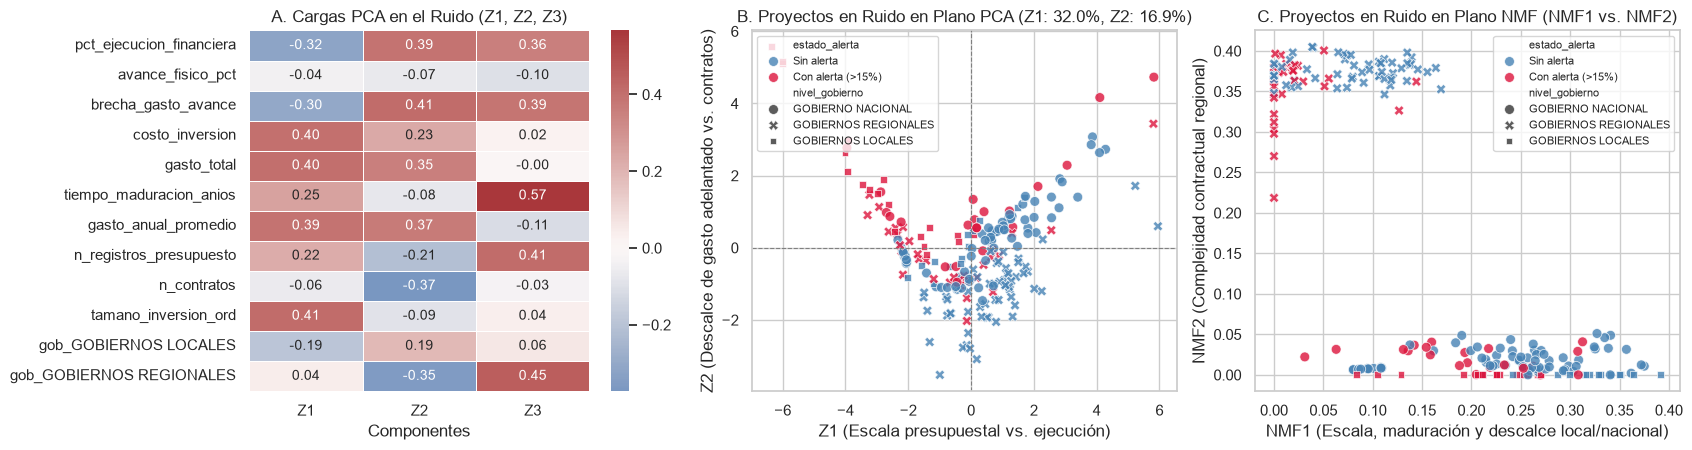

In [7]:
# Filtramos exclusivamente los 215 proyectos marcados como ruido por DBSCAN
df_ruido = df_resultados[df_resultados["cluster_dbscan"] == -1].copy()
X_ruido = df_ruido[features].copy()

# 1. PCA sobre los proyectos de ruido
scaler_ruido = StandardScaler()
X_ruido_std = scaler_ruido.fit_transform(X_ruido)

pca_ruido = PCA()
Z_ruido = pca_ruido.fit_transform(X_ruido_std)
var_exp = pca_ruido.explained_variance_ratio_

tabla_varianza = pd.DataFrame({
    "Componente": [f"Z{i+1}" for i in range(len(var_exp))],
    "Proporcion": var_exp.round(3),
    "Porcentaje_%": (var_exp * 100).round(2),
    "Acumulada_%": (np.cumsum(var_exp) * 100).round(2)
})
print("Varianza explicada por PCA en los 215 proyectos de ruido DBSCAN:")
display(tabla_varianza.head(6))

P_ruido_df = pd.DataFrame(
    pca_ruido.components_.T[:, :3],
    index=features,
    columns=["Z1", "Z2", "Z3"]
)

# 2. NMF (k = 2) sobre los proyectos de ruido
scaler_mm_ruido = MinMaxScaler()
X_ruido_pos = scaler_mm_ruido.fit_transform(X_ruido)

nmf_ruido = NMF(n_components=2, init="nndsvda", random_state=42, max_iter=2000)
W_ruido = nmf_ruido.fit_transform(X_ruido_pos)
H_ruido_df = pd.DataFrame(nmf_ruido.components_, index=["NMF1", "NMF2"], columns=features)

print("Matriz H de NMF sobre los 215 proyectos de ruido (pesos de cada atributo):")
display(H_ruido_df.round(2))

df_ruido["Z1"] = Z_ruido[:, 0]
df_ruido["Z2"] = Z_ruido[:, 1]
df_ruido["NMF1"] = W_ruido[:, 0]
df_ruido["NMF2"] = W_ruido[:, 1]
df_ruido["estado_alerta"] = df_ruido["flag_gasto_adelantado"].map({0: "Sin alerta", 1: "Con alerta (>15%)"})

# Visualizamos las cargas de PCA/NMF y la proyección de los 215 proyectos atípicos
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.heatmap(P_ruido_df, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.5, ax=axes[0])
axes[0].set_title("A. Cargas PCA en el Ruido (Z1, Z2, Z3)")
axes[0].set_xlabel("Componentes")

sns.scatterplot(
    data=df_ruido, x="Z1", y="Z2", hue="estado_alerta", style="nivel_gobierno",
    palette={"Sin alerta": "steelblue", "Con alerta (>15%)": "crimson"}, s=50, alpha=0.8, ax=axes[1]
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title(f"B. Proyectos en Ruido en Plano PCA (Z1: {var_exp[0]*100:.1f}%, Z2: {var_exp[1]*100:.1f}%)")
axes[1].set_xlabel("Z1 (Escala presupuestal vs. ejecución)")
axes[1].set_ylabel("Z2 (Descalce de gasto adelantado vs. contratos)")
axes[1].legend(fontsize=8, loc="upper left")

sns.scatterplot(
    data=df_ruido, x="NMF1", y="NMF2", hue="estado_alerta", style="nivel_gobierno",
    palette={"Sin alerta": "steelblue", "Con alerta (>15%)": "crimson"}, s=50, alpha=0.8, ax=axes[2]
)
axes[2].set_title("C. Proyectos en Ruido en Plano NMF (NMF1 vs. NMF2)")
axes[2].set_xlabel("NMF1 (Escala, maduración y descalce local/nacional)")
axes[2].set_ylabel("NMF2 (Complejidad contractual regional)")
axes[2].legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

## <font color=green>7. Georreferenciación de los proyectos marcados como ruido con GeoPandas y Folium (`mapa_clusters.html`)</font>

Utilizamos la **información marcada como ruido por DBSCAN (`215` proyectos atípicos)** para construir los mapas estáticos en **GeoPandas** y el mapa interactivo **`mapa_clusters.html`** en **Folium**, cruzando los departamentos con los shapefiles oficiales del IGN (`peru_shapes`) en proyección métrica UTM Zona 18S (`EPSG:32718`).

Resumen departamental de los 215 proyectos marcados como ruido (DBSCAN = -1):


,ADM1_PCODE,ADM1_ES,n_proyectos,n_outliers,pct_outliers,n_ruido_alerta,outliers_10mil_km2,costo_outliers_millones,contratos_prom_outliers
14,PE15,Lima,564,89,15.78,22,25.42,23070.29,302.80
7,PE08,Cusco,289,15,5.19,5,2.08,2604.65,470.50
24,PE25,Ucayali,29,13,44.83,1,1.24,1290.01,2287.30
3,PE04,Arequipa,133,10,7.52,1,1.58,4433.12,310.80
4,PE05,Ayacucho,104,8,7.69,3,1.84,694.53,511.50
11,PE12,Junin,79,8,10.13,3,1.81,931.01,757.20
20,PE21,Puno,113,8,7.08,4,1.18,736.57,570.00
0,PE01,Amazonas,62,7,11.29,6,1.78,424.12,345.00
1,PE02,Ancash,98,7,7.14,6,1.95,268.20,99.70
19,PE20,Piura,54,7,12.96,3,1.95,690.31,217.90


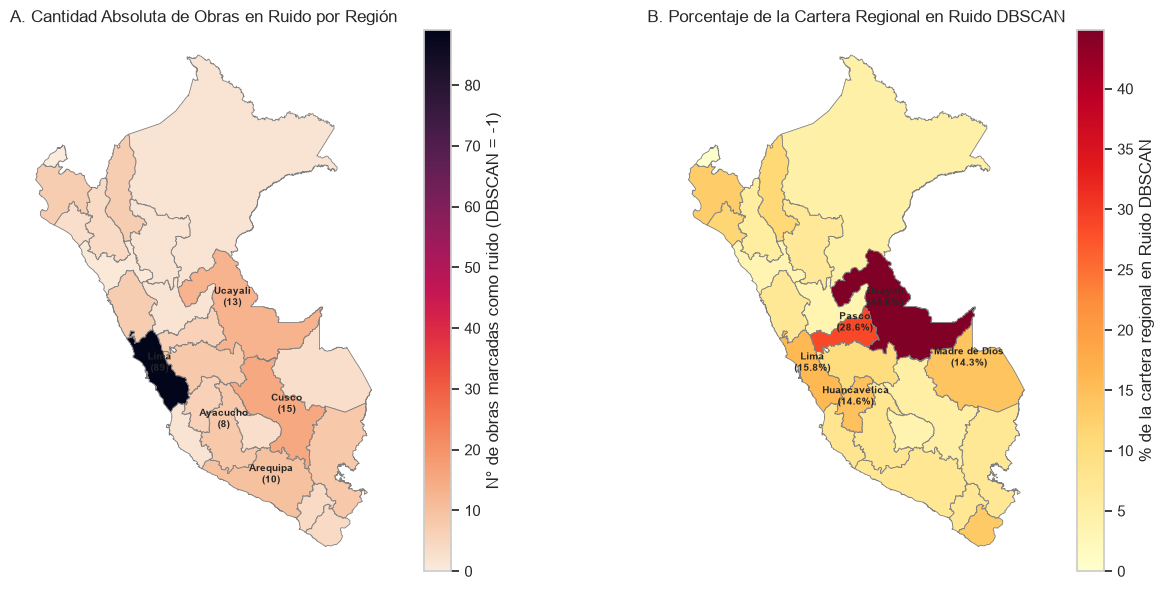

In [8]:
if os.path.exists("peru_shapes"):
    ruta_shapes = "peru_shapes"
else:
    ruta_shapes = "Entrega_4/peru_shapes"

regiones = gpd.read_file(os.path.join(ruta_shapes, "per_admbnda_adm1_ign_20200714.shp"))

# Normalizamos los nombres de departamento para cruzar con ADM1_ES
df_resultados["ADM1_ES"] = (
    df_resultados["departamento"]
    .str.strip()
    .str.title()
    .replace({
        "Provincia Constitucional Del Callao": "Callao",
        "Madre De Dios": "Madre de Dios"
    })
)

df_geo = df_resultados[df_resultados["ADM1_ES"] != ""].copy()
outliers_df = df_geo[df_geo["cluster_dbscan"] == -1].copy()

# 1. Total de obras y conteo de obras en ruido por departamento
resumen_total = (
    df_geo.groupby("ADM1_ES")
    .agg(
        n_proyectos=("codigo_proyecto", "count"),
        cluster_predom=("cluster_kmeans", lambda s: int(s.mode()[0])),
        n_outliers=("es_ruido", "sum"),
        pct_outliers=("es_ruido", lambda s: round(s.mean() * 100, 2))
    )
    .reset_index()
)

# 2. Costo, contratos y alertas dentro de las obras marcadas como ruido por departamento
resumen_ruido_dep = (
    outliers_df.groupby("ADM1_ES")
    .agg(
        n_ruido_alerta=("flag_gasto_adelantado", "sum"),
        costo_outliers_millones=("costo_inversion", lambda s: round(s.sum() / 1e6, 2)),
        contratos_prom_outliers=("n_contratos", lambda s: round(s.mean(), 1))
    )
    .reset_index()
)

# 3. Proyecto en ruido de mayor costo en cada departamento
obra_top_region = (
    outliers_df.sort_values("costo_inversion", ascending=False)
    .groupby("ADM1_ES")
    .first()[["codigo_proyecto", "nombre_proyecto", "costo_inversion"]]
    .reset_index()
)

resumen_regional = (
    resumen_total
    .merge(resumen_ruido_dep, on="ADM1_ES", how="left")
    .merge(obra_top_region, on="ADM1_ES", how="left")
)

# Calculamos el área en km2 reproyectando a coordenadas métricas UTM
crs_metros = regiones.estimate_utm_crs()
regiones_m = regiones.to_crs(crs_metros)
regiones_m["area_km2"] = (regiones_m.area / 1_000_000).round(1)

regiones_outliers = regiones_m.merge(resumen_regional, on="ADM1_ES", how="left")
regiones_outliers["n_proyectos"] = regiones_outliers["n_proyectos"].fillna(0).astype(int)
regiones_outliers["n_outliers"] = regiones_outliers["n_outliers"].fillna(0).astype(int)
regiones_outliers["n_ruido_alerta"] = regiones_outliers["n_ruido_alerta"].fillna(0).astype(int)
regiones_outliers["pct_outliers"] = regiones_outliers["pct_outliers"].fillna(0.0)
regiones_outliers["costo_outliers_millones"] = regiones_outliers["costo_outliers_millones"].fillna(0.0)
regiones_outliers["contratos_prom_outliers"] = regiones_outliers["contratos_prom_outliers"].fillna(0.0)
regiones_outliers["outliers_10mil_km2"] = (
    regiones_outliers["n_outliers"] / regiones_outliers["area_km2"] * 10_000
).round(2)

regiones_outliers["perfil_regional"] = regiones_outliers["cluster_predom"].map({
    0: "Seg. 0: Megaproyectos",
    1: "Seg. 1: Local Municipal Compacto",
    2: "Seg. 2: Regional/Nacional Complejo"
})

print("Resumen departamental de los 215 proyectos marcados como ruido (DBSCAN = -1):")
columnas_tabla = [
    "ADM1_PCODE", "ADM1_ES", "n_proyectos", "n_outliers", "pct_outliers",
    "n_ruido_alerta", "outliers_10mil_km2", "costo_outliers_millones", "contratos_prom_outliers"
]
display(regiones_outliers[columnas_tabla].sort_values("n_outliers", ascending=False).head(12))

# Graficamos los dos mapas estáticos de los proyectos en ruido con GeoPandas
reg_plot = regiones_outliers.to_crs("EPSG:4326")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

reg_plot.plot(
    column="n_outliers",
    cmap="rocket_r",
    edgecolor="gray",
    linewidth=0.6,
    legend=True,
    legend_kwds={"label": "N° de obras marcadas como ruido (DBSCAN = -1)"},
    ax=ax1
)
for _, fila in reg_plot.nlargest(5, "n_outliers").iterrows():
    pto = fila["geometry"].representative_point()
    ax1.text(pto.x, pto.y, f"{fila['ADM1_ES']}\n({fila['n_outliers']})", fontsize=7.5, ha="center", fontweight="bold")
ax1.set_title("A. Cantidad Absoluta de Obras en Ruido por Región")
ax1.set_axis_off()

reg_plot.plot(
    column="pct_outliers",
    cmap="YlOrRd",
    edgecolor="gray",
    linewidth=0.6,
    legend=True,
    legend_kwds={"label": "% de la cartera regional en Ruido DBSCAN"},
    ax=ax2
)
for _, fila in reg_plot.nlargest(5, "pct_outliers").iterrows():
    pto = fila["geometry"].representative_point()
    ax2.text(pto.x, pto.y, f"{fila['ADM1_ES']}\n({fila['pct_outliers']:.1f}%)", fontsize=7.5, ha="center", fontweight="bold")
ax2.set_title("B. Porcentaje de la Cartera Regional en Ruido DBSCAN")
ax2.set_axis_off()

plt.tight_layout()
plt.show()

In [9]:
MAPA_BASE = "OpenStreetMap.France"

regiones_folium = regiones_outliers.copy()
regiones_folium["geometry"] = regiones_folium.to_crs(crs_metros).simplify(1000).to_crs("EPSG:4326")
regiones_folium = regiones_folium.to_crs("EPSG:4326")

# Rellenamos vacíos para las regiones que no registraron outliers
regiones_folium["nombre_proyecto"] = regiones_folium["nombre_proyecto"].fillna("Sin outliers registrados")
regiones_folium["costo_inversion"] = regiones_folium["costo_inversion"].fillna(0.0)

mapa_clusters = folium.Map(
    location=[-9.2, -75.0],
    zoom_start=5,
    tiles=MAPA_BASE,
    width="85%"
)

# Capa 1: Mapa coroplético del porcentaje de proyectos en ruido de DBSCAN por región
folium.Choropleth(
    geo_data=regiones_folium[["ADM1_ES", "pct_outliers", "geometry"]],
    data=regiones_folium,
    columns=["ADM1_ES", "pct_outliers"],
    key_on="feature.properties.ADM1_ES",
    fill_color="YlOrRd",
    fill_opacity=0.65,
    line_weight=0.6,
    legend_name="Porcentaje de obras en ruido DBSCAN (%)",
    name="Capa 1: % Ruido DBSCAN por región"
).add_to(mapa_clusters)

# Capa 2: Marcadores proporcionales al volumen de ruido DBSCAN en cada región
capa_marcadores = folium.FeatureGroup(name="Capa 2: Obras en Ruido DBSCAN y Alertas (clic para popup)")

for _, fila in regiones_folium[regiones_folium["n_proyectos"] > 0].iterrows():
    pto = fila["geometry"].representative_point()
    lat, lon = pto.y, pto.x

    color_pto = "#b30000" if fila["pct_outliers"] >= 14.0 else "#1d3557"

    nombre_obra = str(fila["nombre_proyecto"])[:75]
    if pd.notna(fila["codigo_proyecto"]):
        cui_obra = str(int(fila["codigo_proyecto"]))
    else:
        cui_obra = "-"
    costo_obra_m = fila["costo_inversion"] / 1e6

    texto_popup = (
        f"<b>{fila['ADM1_ES']} ({fila['ADM1_PCODE']})</b><br>"
        f"<b>Obras en Ruido DBSCAN:</b> {fila['n_outliers']} de {fila['n_proyectos']} obras ({fila['pct_outliers']:.1f}%)<br>"
        f"<b>Ruido con alerta (>15%):</b> {fila['n_ruido_alerta']} obras<br>"
        f"<b>Tasa espacial:</b> {fila['outliers_10mil_km2']:.2f} por 10,000 km²<br>"
        f"<b>Costo en ruido:</b> S/ {fila['costo_outliers_millones']:,.1f} M (Prom. {fila['contratos_prom_outliers']:.0f} contratos)<br>"
        f"<b>Perfil K-Means regional:</b> {fila['perfil_regional']}<br>"
        f"<hr>"
        f"<b>Mayor obra en ruido (CUI {cui_obra}):</b><br>{nombre_obra}<br>"
        f"<i>Costo: S/ {costo_obra_m:,.1f} M</i>"
    )

    radio_circulo = 4 + np.sqrt(max(1, fila["n_outliers"])) * 2.2

    folium.CircleMarker(
        location=[lat, lon],
        radius=radio_circulo,
        color=color_pto,
        fill=True,
        fill_color=color_pto,
        fill_opacity=0.80,
        tooltip=f"{fila['ADM1_ES']} · Ruido DBSCAN: {fila['n_outliers']} obras ({fila['pct_outliers']:.1f}%)",
        popup=folium.Popup(texto_popup, max_width=320)
    ).add_to(capa_marcadores)

capa_marcadores.add_to(mapa_clusters)
folium.LayerControl().add_to(mapa_clusters)

if os.path.exists("matriz_analitica_final.csv"):
    ruta_html = "mapa_clusters.html"
else:
    ruta_html = "Entrega_4/mapa_clusters.html"

mapa_clusters.save(ruta_html)
print("Mapa interactivo HTML guardado en:", ruta_html)

mapa_clusters

Mapa interactivo HTML guardado en: mapa_clusters.html


## <font color=green>8. Asignación de proyectos nuevos sin reajustar los modelos</font>

Cuando ingresan nuevos proyectos de inversión al sistema Invierte.pe, los evaluamos con los modelos ya ajustados **sin volver a entrenarlos**:
- **Escalador:** aplicamos `scaler.transform` (nunca `fit_transform`, pues cambiaría la media y desviación estándar de los 2,066 proyectos de referencia).
- **K-Means:** asignamos el segmento con `kmeans_final.predict` y comparamos la distancia a su centroide contra el **umbral del percentil 95 (`4.41`)** de los proyectos históricos para identificar casos que requieren revisión manual.
- **DBSCAN:** como no posee método `.predict()`, aplicamos la regla de vecindad a los **puntos núcleo (`core_sample_indices_`)**: si el proyecto nuevo está a una distancia $\le \varepsilon$ ($1.8$) de algún punto núcleo, toma su grupo; de lo contrario, se etiqueta como **ruido (`-1`)**.

In [10]:
# 1. Calculamos el umbral de distancia al centroide (percentil 95 de los 2,066 proyectos históricos)
dist_historial = kmeans_final.transform(X_std).min(axis=1)
umbral_distancia = np.percentile(dist_historial, 95)
print("Umbral de distancia al centroide (percentil 95):", round(umbral_distancia, 2))

# 2. Simulamos la llegada de 3 proyectos nuevos con perfiles distintos
proyectos_nuevos = pd.DataFrame({
    "id_caso": ["Caso A: Obra municipal regular", "Caso B: Obra regional compleja", "Caso C: Obra con sobregasto y alta fragmentación"],
    "pct_ejecucion_financiera": [62.0, 48.0, 94.0],
    "avance_fisico_pct": [80.0, 68.0, 28.0],
    "brecha_gasto_avance": [-18.0, -20.0, 66.0],
    "costo_inversion": [4_200_000.0, 65_000_000.0, 180_000_000.0],
    "gasto_total": [2_604_000.0, 31_200_000.0, 169_200_000.0],
    "tiempo_maduracion_anios": [6, 12, 16],
    "gasto_anual_promedio": [434_000.0, 2_600_000.0, 10_575_000.0],
    "n_registros_presupuesto": [6, 14, 24],
    "n_contratos": [18.0, 210.0, 950.0],
    "tamano_inversion_ord": [1, 3, 3],
    "gob_GOBIERNOS LOCALES": [1, 0, 0],
    "gob_GOBIERNOS REGIONALES": [0, 1, 1]
})

# Escalamos con el MISMO escalador ya ajustado (transform, nunca fit_transform)
X_nuevos_std = scaler.transform(proyectos_nuevos[features])

# Asignación con K-Means y verificación del umbral de distancia
proyectos_nuevos["segmento_kmeans"] = kmeans_final.predict(X_nuevos_std)
proyectos_nuevos["dist_centroide"] = kmeans_final.transform(X_nuevos_std).min(axis=1).round(2)
proyectos_nuevos["revisar_manual"] = proyectos_nuevos["dist_centroide"] > umbral_distancia

# Asignación con DBSCAN mediante cercanía a puntos núcleo
nucleos = X_std[dbscan_final.core_sample_indices_]
cluster_nucleos = dbscan_final.labels_[dbscan_final.core_sample_indices_]
vecino_nucleo = NearestNeighbors(n_neighbors=1).fit(nucleos)
dist_nucleo, idx_nucleo = vecino_nucleo.kneighbors(X_nuevos_std)

proyectos_nuevos["dbscan_asignado"] = np.where(
    dist_nucleo[:, 0] <= dbscan_final.eps,
    cluster_nucleos[idx_nucleo[:, 0]],
    -1
)

display(proyectos_nuevos[["id_caso", "brecha_gasto_avance", "n_contratos", "segmento_kmeans", "dist_centroide", "revisar_manual", "dbscan_asignado"]])

Umbral de distancia al centroide (percentil 95): 4.41


,id_caso,brecha_gasto_avance,n_contratos,segmento_kmeans,dist_centroide,revisar_manual,dbscan_asignado
0,Caso A: Obra municipal regular,-18.00,18.00,1,1.21,False,2
1,Caso B: Obra regional compleja,-20.00,210.00,2,1.99,False,0
2,Caso C: Obra con sobregasto y alta fragmentación,66.00,950.00,0,5.38,True,-1


# <font color=blue>V. Discusión y Limitaciones</font>

### 1. Relación de los resultados con la pregunta de análisis y utilidad para el usuario
Los resultados confirman que es posible segmentar la cartera de Invierte.pe y caracterizar territorialmente los perfiles de alto riesgo combinando métodos particionales, jerárquicos, de densidad y reducción dimensional focalizada en el ruido:
- **Impacto de descartar el outlier extremo (Línea 2 del Metro):** Retirar `CUI 2233850` (S/ $12,075.45$M) antes de `StandardScaler` evitó que un solo registro distorsionara las distancias euclidianas, permitiendo que **K-Means ($K=3$)** y **Jerárquico Ward ($K=3$)** separen tres grupos reales: **obras locales municipales compactas (Segmento 1, $48.45\%$, $n = 1,001$)**, **obras regionales/nacionales de escala media-alta (Segmento 2, $48.89\%$, $n = 1,010$)** y **megaproyectos de gran envergadura (Segmento 0, $2.66\%$, $n = 55$, S/ $526.0$M promedio)**.
- **Significado del ruido de DBSCAN y su descomposición con PCA/NMF para la Contraloría:** Mientras que en los clusters densos ($n = 1,851$) la tasa de alerta de gasto adelantado es de $11.40\%$, en los **215 proyectos aislados como ruido por DBSCAN ($10.41\%$)** la tasa de alerta crítica sube a **$33.02\%$** (con una brecha media positiva de $+9.24\%$ y $467.5$ contratos promedio). Al aplicar **PCA y NMF sobre estos 215 proyectos de ruido**, demostramos que el ruido no es homogéneo, sino que agrupa tres patologías diferenciables: (1) megaproyectos con larga maduración, (2) obras con descalce financiero severo (`brecha_gasto_avance` alta) y (3) obras regionales con excesiva fragmentación contractual (`NMF2`).
- **Focalización territorial en Folium (`mapa_clusters.html`):** El mapa interactivo del ruido muestra que **Lima** concentra el mayor volumen absoluto ($89$ obras en ruido, S/ $23,070.3$M), mientras que **Ucayali ($44.83\%$)**, **Pasco ($28.57\%$)** y **Huancavelica ($14.63\%$)** registran la mayor proporción relativa de su cartera en condición anómala.

### 2. Limitaciones del estudio
1. **Limitaciones de los datos:** La ubicación geográfica en la matriz integrada se encuentra a nivel departamental (`ADM1_ES`), por lo que la georreferenciación en Folium asigna los indicadores al polígono y punto representativo regional y no a la coordenada GPS individual de cada obra. Asimismo, el porcentaje de avance físico depende de la periodicidad con que los supervisores actualizan las valorizaciones en Infobras.
2. **Limitaciones de la técnica:** K-Means asume fronteras convexas y asigna obligatoriamente toda observación a un centroide, por lo que requiere complementarse con el percentil 95 de distancia ($4.41$) o con DBSCAN para aislar anomalías. A su vez, DBSCAN emplea un único umbral de densidad ($arepsilon = 1.8$), que puede resultar exigente para departamentos con carteras pequeñas.
3. **Limitaciones de la evaluación:** El coeficiente de Silhouette global ($0.221$) y la presencia de valores negativos en el Segmento 2 indican que entre las obras medianas municipales y regionales existe una transición continua; por tanto, los segmentos deben emplearse como **perfiles operativos de tendencia**.

# <font color=blue>VI. Conclusiones, Recomendaciones y Trabajo Futuro</font>

### 1. Conclusiones
1. **Respuesta a la pregunta de investigación:** Sí es posible identificar tipologías estructurales de proyectos de inversión y caracterizar territorialmente perfiles atípicos de descalce financiero-físico a partir de los datos transaccionales del MEF. Tras descartar el outlier extremo de la Línea 2 del Metro ($N = 2,066$), la triangulación de métricas internas (codo de inercia de $-16.00\%$, máximo de Silhouette en $0.221$ y mínimo local de Davies-Bouldin en $1.479$, frente al deterioro en $K=4$ con Silhouette $0.211$ y DB $1.607$) converge en **$K = 3$ segmentos** consistentes entre K-Means y Ward (`1,078 / 960 / 28`), separando obras locales compactas ($n = 1,001$, `silueta_media = 0.328` sin valores negativos), obras regionales/nacionales complejas ($n = 1,010$) y megaproyectos ($n = 55$).
2. **Interpretación de anomalías mediante PCA y NMF sobre el ruido de DBSCAN:** DBSCAN ($arepsilon = 1.8, \text{MinPts} = 24$) aisló **215 proyectos como ruido ($10.41\%$)** con **$33.02\%$** de alerta de gasto adelantado (frente a $11.40\%$ en los clusters densos). Aplicar **PCA ($61.83\%$ de varianza en 3 ejes) y NMF ($k=2$)** directamente sobre estos 215 outliers permitió distinguir las anomalías por sobregasto adelantado (`Z2` / `NMF1`) de aquellas por fraccionamiento contractual en gobiernos regionales (`NMF2`).
3. **Georreferenciación del ruido en GeoPandas y Folium:** El despliegue de los 215 proyectos de ruido en `mapa_clusters.html` evidencia que el riesgo combina alta concentración presupuestal en **Lima** ($89$ obras en ruido, S/ $23,070.3$M) con una crítica incidencia porcentual en **Ucayali ($44.83\%$ de su cartera en ruido, $2,287$ contratos promedio)** y **Pasco ($28.57\%$)**.

### 2. Recomendaciones para el usuario
1. **Para la Contraloría General de la República:** Implementar un filtro mensual de alerta temprana que envíe automáticamente a control concurrente a los proyectos que DBSCAN clasifique como ruido (`-1`) o cuya distancia al centroide en K-Means supere el percentil 95 ($4.41$).
2. **Para la DGPMI - MEF y el OSCE:** Realizar operativos de auditoría sobre el fraccionamiento contractual en las unidades ejecutoras de **Ucayali, Pasco y Huancavelica**, estableciendo alertas en el SEACE cuando un CUI supere el promedio de contratos de su segmento ($> 211$ contratos en obras regionales/nacionales o $> 123$ en obras locales).
3. **Para los Gobiernos Regionales y Locales:** Diferenciar los protocolos de monitoreo: aplicar plantillas de liquidación ágil para el Segmento 1 y exigir conciliación trimestral obligatoria entre devengado SIAF y valorización física Infobras para los Segmentos 0 y 2.

### 3. Trabajo futuro
- Integrar las coordenadas GPS exactas (latitud y longitud por obra) desde el padrón de Infobras para ejecutar **DBSCAN espacial en metros** (`eps` en kilómetros) y mapas de calor continuos (`HeatMap`) a nivel distrital.
- Incorporar la serie temporal mensual de desembolsos y valorizaciones para modelar la velocidad a la que se abre la brecha de gasto antes de que una obra quede paralizada.
- Aplicar reglas de asociación sobre las causales de adendas y ampliaciones de plazo registradas en el SEACE.

In [11]:
columnas_exportar = [
    "codigo_proyecto", "nombre_proyecto", "nivel_gobierno", "departamento",
    "pct_ejecucion_financiera", "avance_fisico_pct", "brecha_gasto_avance",
    "costo_inversion", "gasto_total", "tiempo_maduracion_anios",
    "gasto_anual_promedio", "n_registros_presupuesto", "n_contratos",
    "flag_gasto_adelantado", "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES", "gob_GOBIERNOS REGIONALES",
    "cluster_kmeans", "silhouette_km", "cluster_dbscan", "cluster_hier"
]

if os.path.exists("matriz_analitica_final.csv"):
    ruta_salida = "matriz_analitica_con_clusters.csv"
else:
    ruta_salida = "Entrega_4/matriz_analitica_con_clusters.csv"

df_resultados[columnas_exportar].to_csv(ruta_salida, index=False)

print("Matriz analítica final con clusters guardada en:", ruta_salida)
print("Dimensiones:", df_resultados[columnas_exportar].shape)
display(df_resultados[["codigo_proyecto", "nombre_proyecto", "departamento", "cluster_kmeans", "cluster_dbscan", "cluster_hier"]].head(5))

Matriz analítica final con clusters guardada en: matriz_analitica_con_clusters.csv
Dimensiones: (2066, 21)


,codigo_proyecto,nombre_proyecto,departamento,cluster_kmeans,cluster_dbscan,cluster_hier
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,LIMA,0,-1,2
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,LIMA,0,-1,2
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,ANCASH,2,-1,2
3,2015918,PROYECTO VIAL TACNA LA PAZ,TACNA,0,-1,2
4,2017383,MEJORAMIENTO Y AMPLIACION DE LOS SISTEMAS DE A...,JUNIN,2,0,2
